# Xấp xỉ hàm Gauss 2D bằng MLP (PyTorch)

Phụ trách: Huỳnh Ngọc Trúc (Nhóm 05)

Bản PyTorch của `Yêu cầu/examples/1. MLP/Func_apxm_MLP.ipynb`, giữ nguyên thứ tự mục và cấu hình của gốc.

- Hàm cần xấp xỉ: mật độ Gauss 2 chiều, kỳ vọng (0, 0), hiệp phương sai đơn vị, trên miền [−3, 3]².
- Mô hình `gauss_mlp(B)`: 2 → B nút sigmoid → 1 nút sigmoid. Loss MSE, SGD lr 0.01, batch 128.
- Ba vòng quét: (4.1) số mẫu train A, (4.2) số nút ẩn B, (4.3) số epoch C.

Notebook gốc **chỉ có hình, không in số**. Đọc gần đúng từ hình gốc (để so độ lớn):

| Vòng quét | Điểm cuối | Train MSE gốc | Test MSE gốc | Hình gốc chạy bằng |
|---|---|---|---|---|
| A | A = 1000 | ≈ 0,0063 | ≈ 0,0067 | tf.keras 2.14 |
| B | B = 512 | ≈ 0,0014 | ≈ 0,0014 | Keras cũ |
| C | C = 190 | ≈ 0,0016 | ≈ 0,0016 | Keras cũ |

Bài toán này trùng BTL01 (đã nộp), nhưng notebook này bám đúng cấu hình của notebook gốc (sigmoid, SGD 0.01, batch 128), không dùng cấu hình BTL01.

# (1) import libraries

Keras gốc:
```python
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal
import pandas as pd

# True: chỉ chạy thử (epoch chia 10) để kiểm code; bản nộp phải là False
CHAY_THU = False

set_seed(0)
device = get_device()
TEN = "Func_apxm_MLP"   # results/Func_apxm_MLP/

torch 2.15.0+cpu | thiết bị: cpu


# (2) data preparation

Giữ nguyên code numpy của gốc: lưới train 32×32 = 1024 điểm, lưới test 10×10 = 100 điểm. Chỉ thêm bước đổi sang tensor float32 ở cuối (Keras tự đổi khi `fit`).

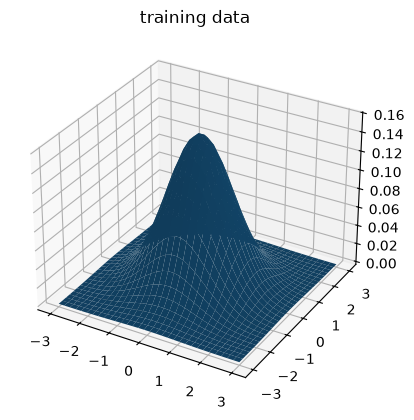

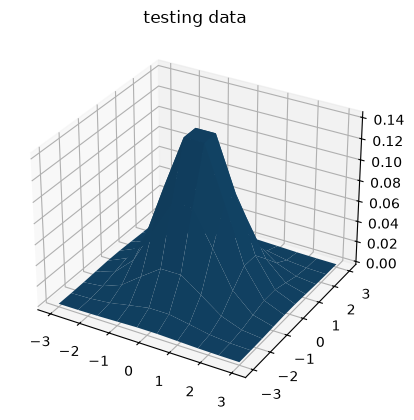

In [2]:
# training ------------------------------
A = 32j
x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])

mu = np.array([0.0, 0.0])
covariance = np.diag([1, 1])

y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance)
y = y.reshape(x1.shape)

x_train = x1x2
y_train = y.flatten()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, y)
plt.title('training data')
plt.show()

# testing -------------------------------
A = 10j

x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])

y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance)
y = y.reshape(x1.shape)

x_test = x1x2
y_test = y.flatten()

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, y)
plt.title('testing data')
plt.show()

In [3]:
# numpy float64 → tensor float32. Nhãn để shape (N, 1) cho khớp đầu ra (N, 1) của mô hình:
# nếu để (N,), nn.MSELoss sẽ broadcast thành ma trận (N, N) và cho loss sai.
X_train = torch.tensor(x_train, dtype=torch.float32)               # (1024, 2)
Y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # (1024, 1)
X_test = torch.tensor(x_test, dtype=torch.float32)                 # (100, 2)
Y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)    # (100, 1)
print(X_train.shape, Y_train.shape, X_test.shape, Y_test.shape)
print("y lớn nhất: %.4f, trung bình: %.4f" % (y_train.max(), y_train.mean()))

torch.Size([1024, 2]) torch.Size([1024, 1]) torch.Size([100, 2]) torch.Size([100, 1])
y lớn nhất: 0.1577, trung bình: 0.0260


# (3) MLP

Keras gốc:
```python
def gauss_mlp(B=16):
    inp = Input(shape=(2,), name='Input')
    x = Dense(units=B, activation='sigmoid', name='fc')(inp)
    gauss_out = Dense(units=1, activation='sigmoid', name='gauss_apxm')(x)
    model = Model(inputs=inp, outputs=gauss_out, name='gauss_mlp')
    return model
```

Đầu ra có sigmoid (bài hồi quy, giá trị trong (0, 1)), nên `forward` giữ sigmoid ở lớp cuối, khác các bài phân loại.

In [4]:
class GaussMLP(nn.Module):
    """gauss_mlp: 2 → B (sigmoid) → 1 (sigmoid)."""

    def __init__(self, B=16):
        super().__init__()
        self.fc = nn.Linear(2, B)            # 2·B + B tham số
        self.gauss_apxm = nn.Linear(B, 1)    # B + 1 tham số

    def forward(self, x):                    # x: (N, 2)
        x = torch.sigmoid(self.fc(x))        # (N, B)
        return torch.sigmoid(self.gauss_apxm(x))   # (N, 1)


def gauss_mlp(B=16):
    return init_keras_like(GaussMLP(B)).to(device)   # glorot uniform, bias 0 như Keras


m = gauss_mlp(16)
summary(m, input_size=(1, 2))
assert count_params(m) == 2 * 16 + 16 + 16 + 1   # = 65

# (4) training and evaluating MLP

Ba vòng quét của gốc lặp lại cùng một đoạn: tạo mô hình → `compile(loss='mean_squared_error', optimizer=SGD(lr=0.01))` → chọn A mẫu → `fit(batch_size=128, epochs=C, validation_data=(x_test, y_test), verbose=0)` → `evaluate` trên **toàn bộ** tập train và tập test. Ở đây gom đoạn đó vào hàm `train_and_evaluate(A, B, C)` để ba vòng quét gọn hơn; nội dung từng bước giữ nguyên.

Hai điểm giữ đúng như gốc và cần biết khi đọc kết quả:
- `sel_indx = np.random.choice(range(1, tot_train), ...)` với `tot_train = 1001` chỉ chọn trong điểm 1…1000, nên điểm 0 và các điểm 1001–1023 không bao giờ được dùng để train (nhưng vẫn được tính trong train error).
- Train error đo trên cả 1024 điểm, không chỉ A điểm đã dùng để train.

In [5]:
tot_train = 1001
loss_fn = nn.MSELoss()            # = 'mean_squared_error'
lr = 0.01
batch_size = 128
test_loader = make_loader(X_test, Y_test, batch_size=batch_size)
full_train_loader = make_loader(X_train, Y_train, batch_size=batch_size)


def train_and_evaluate(A, B, C):
    """Một lần huấn luyện như trong vòng lặp gốc; trả (train MSE, test MSE)."""
    model = gauss_mlp(B=B)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    epochs = max(1, C // 10) if CHAY_THU else C

    # items for training (giữ range(1, 1001) như gốc)
    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)
    train_loader = make_loader(X_train[sel_indx], Y_train[sel_indx], batch_size=batch_size, shuffle=True)
    fit(model, train_loader, test_loader, loss_fn, optimizer, epochs, verbose=0)

    train_err, _ = evaluate(model, full_train_loader, loss_fn)
    test_err, _ = evaluate(model, test_loader, loss_fn)
    return train_err, test_err


def ve_quet(values, train_error, test_error, title, xlabel, ten_file):
    plt.plot(values, train_error, label='training')
    plt.plot(values, test_error, label='testing')
    plt.legend()
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Error')
    if not CHAY_THU:
        plt.savefig(results_dir(TEN) / ten_file, dpi=150, bbox_inches="tight")
    plt.show()

### (4.1) Number of training samples (A) (no. of hidden nodes (B) = 16 and no. of epochs (C) = 100)

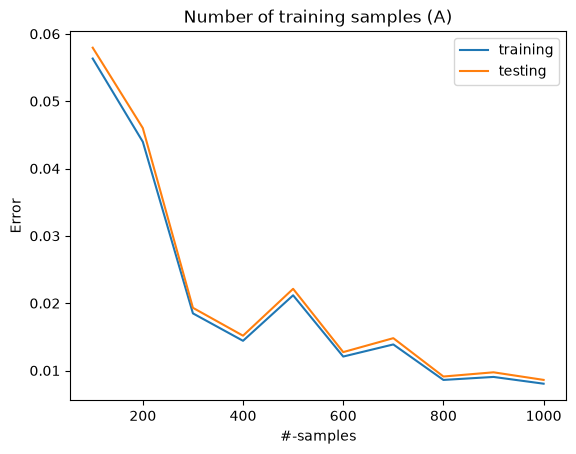

thời gian: 6.8 s


,A,train_mse,test_mse
0,100,0.056331,0.057942
1,200,0.043965,0.046004
2,300,0.018484,0.019311
3,400,0.014411,0.015170
4,500,0.021170,0.022130
5,600,0.012071,0.012732
6,700,0.013870,0.014802
7,800,0.008599,0.009106
8,900,0.009045,0.009732
9,1000,0.008040,0.008605


In [6]:
train_error, test_error, A_array = [], [], []
B, C = 16, 100
t0 = time.time()
for A in np.arange(100, tot_train, 100):
    tr, te = train_and_evaluate(int(A), B, C)
    train_error.append(tr); test_error.append(te); A_array.append(int(A))
time_A = time.time() - t0

ve_quet(A_array, train_error, test_error, 'Number of training samples (A)', '#-samples', 'quet_A.png')
quet_A = pd.DataFrame({"A": A_array, "train_mse": train_error, "test_mse": test_error})
print("thời gian: %.1f s" % time_A)
quet_A

### (4.2) Number of hidden nodes (B) (no. of training samples (A) = 800 and no. of epochs (C) = 100)

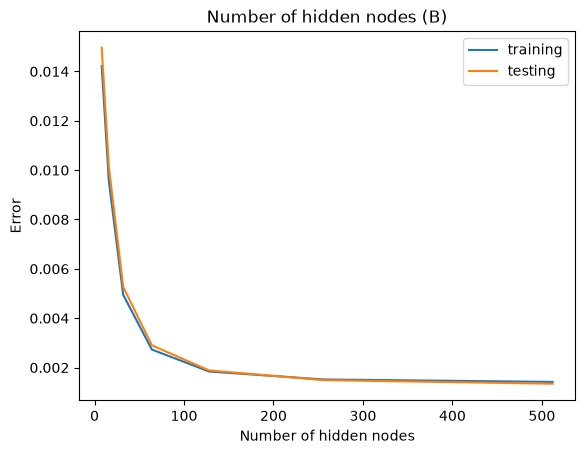

thời gian: 5.4 s


,B,train_mse,test_mse
0,8,0.014220,0.014961
1,16,0.009555,0.010129
2,32,0.004948,0.005272
3,64,0.002732,0.002903
4,128,0.001839,0.001884
5,256,0.001518,0.001491
6,512,0.001419,0.001346


In [7]:
train_error, test_error, B_array = [], [], []
A, B, C = 800, 8, 100
t0 = time.time()
while B <= 512:
    tr, te = train_and_evaluate(A, B, C)
    train_error.append(tr); test_error.append(te); B_array.append(B)
    B *= 2
time_B = time.time() - t0

ve_quet(B_array, train_error, test_error, 'Number of hidden nodes (B)', 'Number of hidden nodes', 'quet_B.png')
quet_B = pd.DataFrame({"B": B_array, "train_mse": train_error, "test_mse": test_error})
print("thời gian: %.1f s" % time_B)
quet_B

### (4.3) Number of epochs (C) (no. of training samples (A) = 800 and no. of hidden nodes (B) = 128)

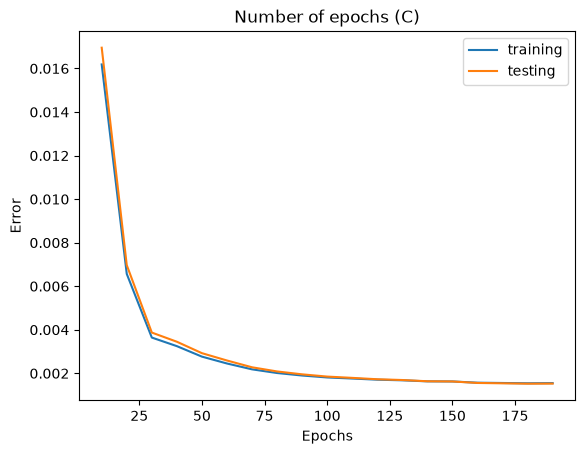

thời gian: 13.8 s


,C,train_mse,test_mse
0,10,0.016186,0.016954
1,20,0.006565,0.006969
2,30,0.003642,0.003872
3,40,0.003248,0.003450
4,50,0.002767,0.002926
5,60,0.002451,0.002589
6,70,0.002183,0.002277
7,80,0.002014,0.002086
8,90,0.001899,0.001953
9,100,0.001810,0.001850


In [8]:
train_error, test_error, C_array = [], [], []
A, B = 800, 128
t0 = time.time()
for C in np.arange(10, 200, 10):
    tr, te = train_and_evaluate(A, B, int(C))
    train_error.append(tr); test_error.append(te); C_array.append(int(C))
time_C = time.time() - t0

ve_quet(C_array, train_error, test_error, 'Number of epochs (C)', 'Epochs', 'quet_C.png')
quet_C = pd.DataFrame({"C": C_array, "train_mse": train_error, "test_mse": test_error})
print("thời gian: %.1f s" % time_C)
quet_C

# Lưu kết quả

Mỗi vòng quét ghi một file `quet_A/B/C.csv` và một dòng trong `results/so_sanh.csv` (test MSE ở điểm cuối của vòng quét). Cột Keras để trống vì gốc không in số; số đọc từ hình gốc ghi ở cột `ghi_chu`.

In [9]:
if not CHAY_THU:
    d = results_dir(TEN)
    quet_A.to_csv(d / "quet_A.csv", index=False)
    quet_B.to_csv(d / "quet_B.csv", index=False)
    quet_C.to_csv(d / "quet_C.csv", index=False)
    save_metrics(TEN, quet_A_test_mse_A1000=quet_A.test_mse.iloc[-1],
                 quet_B_test_mse_B512=quet_B.test_mse.iloc[-1],
                 quet_C_test_mse_C190=quet_C.test_mse.iloc[-1],
                 train_time_s=time_A + time_B + time_C, device=device_name(device), seed=0)
    chung = dict(optimizer="SGD", lr=lr, batch=batch_size, device=device_name(device), seed=0)
    ghi_so_sanh("Func_apxm_MLP_A", "1. MLP", "test_mse", keras=None, pytorch=quet_A.test_mse.iloc[-1],
                keras_params=65, pytorch_params=count_params(gauss_mlp(16)), epochs_keras=100, epochs_pytorch=100,
                train_time_s=time_A, ghi_chu="Quét A=100..1000 (B=16, C=100); giá trị tại A=1000; "
                "gốc chỉ có hình (TensorFlow 2.14), đọc từ hình test ≈ 0.0067", **chung)
    ghi_so_sanh("Func_apxm_MLP_B", "1. MLP", "test_mse", keras=None, pytorch=quet_B.test_mse.iloc[-1],
                keras_params=2049, pytorch_params=count_params(gauss_mlp(512)), epochs_keras=100, epochs_pytorch=100,
                train_time_s=time_B, ghi_chu="Quét B=8..512 (A=800, C=100); giá trị tại B=512; "
                "gốc chỉ có hình (Keras cũ), đọc từ hình test ≈ 0.0014", **chung)
    ghi_so_sanh("Func_apxm_MLP_C", "1. MLP", "test_mse", keras=None, pytorch=quet_C.test_mse.iloc[-1],
                keras_params=513, pytorch_params=count_params(gauss_mlp(128)), epochs_keras=190, epochs_pytorch=190,
                train_time_s=time_C, ghi_chu="Quét C=10..190 (A=800, B=128); giá trị tại C=190; "
                "gốc chỉ có hình (Keras cũ), đọc từ hình test ≈ 0.0016", **chung)

so_sanh.csv: Func_apxm_MLP_A | test_mse Keras (chỉ có hình) | PyTorch 0.0086 | chênh -
so_sanh.csv: Func_apxm_MLP_B | test_mse Keras (chỉ có hình) | PyTorch 0.0013 | chênh -
so_sanh.csv: Func_apxm_MLP_C | test_mse Keras (chỉ có hình) | PyTorch 0.0015 | chênh -
